# Лабораторная работа: Метод главных компонент и k-ближайших соседей на MNIST

## О задании

В этой работе вы:
1. Реализуете **метод главных компонент (PCA)** — один из базовых методов понижения размерности
2. Реализуете **метод k-ближайших соседей (kNN)** — простейший метрический классификатор
3. Примените оба метода для распознавания рукописных цифр из базы **MNIST**
4. Исследуете, как понижение размерности влияет на качество классификации

---

## Часть 0. Подготовка данных (обязательно, но без баллов)

### Теория: Что такое MNIST?

**MNIST** (Modified National Institute of Standards and Technology) — это классический датасет для задач распознавания рукописных цифр. Он состоит из:
- **70 000 изображений** рукописных цифр от 0 до 9
- Каждое изображение имеет размер **28×28 пикселей** (784 признака)
- **60 000** изображений для обучения, **10 000** для тестирования

Каждое изображение — это матрица 28×28, где каждый пиксель — число от 0 (чёрный) до 255 (белый).

### Задание 0.1: Загрузка данных

```python
import numpy as np
import matplotlib.pyplot as plt
from mnist import load_mnist

# Загружаем данные
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
```

**Вопрос:** Какова размерность одного изображения? Сколько всего признаков у каждого объекта?

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mnist import load_mnist

# Загружаем данные (при первом запуске скачиваются в папку MNIST-data)
train, validation, test = load_mnist()

# Извлекаем картинки и метки
X_train_full, y_train_full = train
X_val, y_val = validation
X_test, y_test = test

print(f"Размер обучающей выборки: {X_train_full.shape}")
print(f"Размер валидационной выборки: {X_val.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Extracting MNIST-data\train-images-idx3-ubyte.gz


Extracting MNIST-data\train-labels-idx1-ubyte.gz
Extracting MNIST-data\t10k-images-idx3-ubyte.gz
Extracting MNIST-data\t10k-labels-idx1-ubyte.gz
Размер обучающей выборки: (55000, 28, 28, 1)
Размер валидационной выборки: (5000, 28, 28, 1)
Размер тестовой выборки: (10000, 28, 28, 1)


**Ответ.** Одно изображение имеет размер **28×28 пикселей** (в массиве форма `(28, 28, 1)`, последний канал — оттенки серого), т.е. у каждого объекта **28·28 = 784 признака** (яркости пикселей). Функция `load_mnist` из `mnist.py` отдаёт 55 000 обучающих, 5 000 валидационных (взяты из исходной обучающей части) и 10 000 тестовых изображений.

### Задание 0.2: Визуализация примеров

Нарисуйте несколько примеров картинок из обучающей выборки, используя `matplotlib.pyplot.subplots`.

**Подсказка:** Изображения хранятся в формате `(n_samples, 28, 28, 1)`. Для отображения используйте `plt.imshow(img.reshape(28, 28), cmap='gray')`.

```python
# TODO: Нарисуйте 10 примеров (по одному на каждую цифру)
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
# Ваш код здесь
```

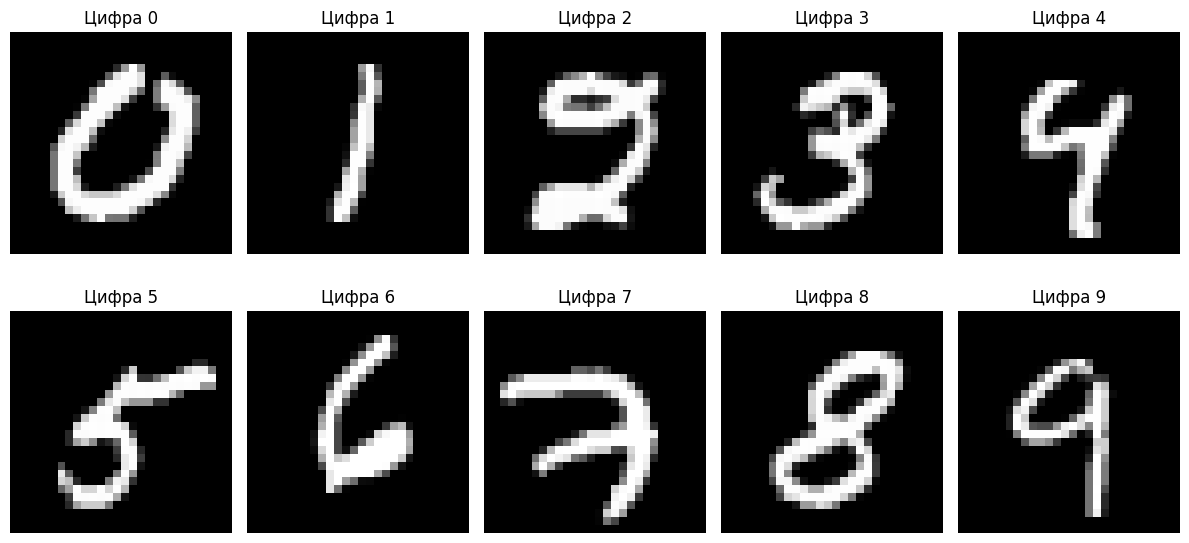

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for digit, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == digit)[0][0]      # первый пример этой цифры
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f"Цифра {digit}")
    ax.axis('off')
plt.tight_layout()
plt.show()

### Задание 0.3: Подготовка данных

Для дальнейшей работы:
1. Объедините обучающую и валидационную выборки
2. Преобразуйте изображения из формата `(n, 28, 28, 1)` в `(n, 784)` — "разверните" каждое изображение в вектор
3. Нормализуйте значения пикселей в диапазон [0, 1] (разделите на 255)

```python
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
```

In [3]:
# Объединяем train и validation
X = np.concatenate([X_train_full, X_val], axis=0)
y = np.concatenate([y_train_full, y_val], axis=0)

# Преобразуем форму: (n, 28, 28, 1) -> (n, 784)
X = X.reshape(X.shape[0], -1)

# Нормализуем
X = X.astype(np.float32) / 255.0

print(f"Форма X: {X.shape}")
print(f"Форма y: {y.shape}")
print(f"Уникальные классы: {np.unique(y)}")
print(f"Диапазон значений: [{X.min()}, {X.max()}]")

Форма X: (60000, 784)
Форма y: (60000,)
Уникальные классы: [0 1 2 3 4 5 6 7 8 9]
Диапазон значений: [0.0, 1.0]


## Часть 1. Метод главных компонент (PCA)

### Теория: Зачем нужен PCA?

**Проблема:** У нас 784 признака (пикселя) на каждое изображение. Многие из них **коррелированы** (соседние пиксели часто имеют похожие значения), а некоторые **неинформативны** (например, углы картинки почти всегда чёрные).

**Идея PCA:** Найти такие **новые оси** (главные компоненты), вдоль которых данные **сильнее всего разбросаны**. Тогда:
- Несколько первых компонент опишут **большую часть** информации
- Остальные компоненты можно **отбросить** без существенной потери качества

### Математика PCA

Пусть у нас есть матрица данных $X \in \mathbb{R}^{n \times d}$ (n объектов, d признаков).

**Шаг 1. Центрирование.** Вычитаем среднее по каждому признаку:
$$ X_{centered} = X - \bar{X} $$
где $\bar{X}$ — вектор средних значений по каждому столбцу.

**Шаг 2. Матрица ковариации:**
$$ C = \frac{1}{n-1} X_{centered}^T X_{centered} \in \mathbb{R}^{d \times d} $$

**Шаг 3. Собственные векторы и значения.** Находим:
$$ C v_i = \lambda_i v_i $$
где $\lambda_1 \ge \lambda_2 \ge ... \ge \lambda_d$ — собственные значения, $v_i$ — собственные векторы.

**Шаг 4. Преобразование.** Новые координаты объекта:
$$ Y = X_{centered} \cdot V_k $$
где $V_k$ — матрица из первых $k$ собственных векторов.

### Важная связь: собственные числа и дисперсия

**Собственное число $\lambda_i$ равно дисперсии данных вдоль $i$-й главной компоненты.**

Доля объяснённой дисперсии для $k$ первых компонент:
$$ \text{Explained Variance Ratio} = \frac{\sum_{i=1}^{k} \lambda_i}{\sum_{i=1}^{d} \lambda_i} $$

---

### Задание 1.1: Реализация my_PCA

Реализуйте класс `my_PCA`, аналогичный `sklearn.decomposition.PCA`.

```python
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None       # главные компоненты (собственные векторы)
        self.explained_variance_ = None  # собственные значения
        self.mean_ = None             # среднее по каждому признаку
        
    def fit(self, X):
        """
        Обучает PCA на данных X.
        
        Шаги:
        1. Центрировать данные
        2. Вычислить матрицу ковариации (или использовать SVD)
        3. Найти собственные векторы и значения
        4. Отсортировать по убыванию собственных значений
        5. Сохранить первые n_components компонент
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        """
        # TODO: Реализуйте обучение
        
        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # Шаг 2-3: Используйте np.linalg.svd (рекомендуется!) или np.linalg.eig
        # SVD: X_centered = U @ S @ Vt
        # Собственные значения ковариации = S^2 / (n-1)
        # Собственные векторы = Vt.T
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        # TODO: Сохраните собственные значения и векторы
        # explained_variance = S^2 / (n - 1)
        # components = Vt
        
        # TODO: Отсортируйте (SVD уже возвращает в порядке убывания)
        # TODO: Если n_components задано, оставьте только первые n_components
        
        return self
    
    def transform(self, X):
        """
        Преобразует данные в координаты главных компонент.
        
        Y = (X - mean) @ components[:n_components].T
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        Y : np.array, shape (n_samples, n_components)
        """
        # TODO: Реализуйте преобразование
        pass
    
    def fit_transform(self, X):
        """
        Обучает и сразу преобразует.
        """
        return self.fit(X).transform(X)
```

**Подсказка:** Для реализации рекомендуется использовать **SVD** (сингулярное разложение), а не `np.linalg.eig`. Это численно устойчивее и работает быстрее.

In [4]:
class my_PCA:
    def __init__(self, n_components=None):
        """
        Parameters
        ----------
        n_components : int or None
            Количество главных компонент. Если None, сохраняются все.
        """
        self.n_components = n_components
        self.components_ = None                # главные компоненты (собственные векторы), shape (k, d)
        self.explained_variance_ = None        # собственные значения, shape (k,)
        self.explained_variance_ratio_ = None  # доля объяснённой дисперсии каждой компоненты
        self.mean_ = None                      # среднее по каждому признаку

    def fit(self, X):
        """
        Обучает PCA на данных X, shape (n_samples, n_features).
        """
        n = X.shape[0]

        # Шаг 1: Центрирование
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Шаг 2-3: SVD центрированных данных: X_centered = U @ diag(S) @ Vt.
        # Тогда C = X_c^T X_c / (n-1) = V diag(S^2/(n-1)) V^T, т.е.
        # собственные векторы C - строки Vt, собственные значения - S^2 / (n-1).
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        eigenvalues = S**2 / (n - 1)

        # Шаг 4: SVD уже возвращает сингулярные числа по убыванию - сортировка не нужна
        # Шаг 5: оставляем первые n_components
        k = len(S) if self.n_components is None else self.n_components
        self.components_ = Vt[:k]
        self.explained_variance_ = eigenvalues[:k]
        self.explained_variance_ratio_ = eigenvalues[:k] / eigenvalues.sum()
        return self

    def transform(self, X):
        """
        Y = (X - mean) @ components.T, shape (n_samples, n_components)
        """
        return (X - self.mean_) @ self.components_.T

    def fit_transform(self, X):
        return self.fit(X).transform(X)

### Задание 1.2: Проверка реализации

Убедитесь, что ваш PCA работает правильно, сравнив его с `sklearn.decomposition.PCA`:

```python
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

# Проверьте, что результаты близки (с точностью до знака)
print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")

# Проверка: результат должен совпадать с точностью до знака
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")
```

**Вопрос:** Совпадают ли собственные значения? Если да, то ваша реализация верна.

In [5]:
from sklearn.decomposition import PCA

# Обучите оба PCA на одних данных
my_pca = my_PCA(n_components=50)
sk_pca = PCA(n_components=50)

Y_my = my_pca.fit_transform(X[:1000])
Y_sk = sk_pca.fit_transform(X[:1000])

print(f"Сумма собственных значений (my): {my_pca.explained_variance_.sum():.2f}")
print(f"Сумма собственных значений (sklearn): {sk_pca.explained_variance_.sum():.2f}")
print(f"Форма Y_my: {Y_my.shape}")
print(f"Форма Y_sk: {Y_sk.shape}")

# Подробная проверка. Важно: при n_components=50 sklearn по умолчанию (svd_solver='auto')
# выбирает ПРИБЛИЖЁННЫЙ рандомизированный SVD, поэтому малые компоненты немного отличаются.
print("Решатель sklearn по умолчанию:", sk_pca._fit_svd_solver)
rel = np.abs(my_pca.explained_variance_ - sk_pca.explained_variance_) / sk_pca.explained_variance_
print(f"Макс. относительное отличие собственных значений (randomized): {rel.max():.2e}")

# Сравнение с точным решателем sklearn
sk_full = PCA(n_components=50, svd_solver='full')
Y_full = sk_full.fit_transform(X[:1000])
rel_full = np.abs(my_pca.explained_variance_ - sk_full.explained_variance_) / sk_full.explained_variance_
cos = np.abs(np.sum(my_pca.components_ * sk_full.components_, axis=1))   # |косинус| между компонентами
print(f"\nС точным решателем (svd_solver='full'):")
print(f"  макс. относительное отличие собственных значений: {rel_full.max():.2e}")
print(f"  мин. |cos| между соответствующими компонентами:  {cos.min():.6f}")
print("  проекции совпадают с точностью до знака:", np.allclose(np.abs(Y_my), np.abs(Y_full), atol=1e-3))

Сумма собственных значений (my): 45.48
Сумма собственных значений (sklearn): 45.48
Форма Y_my: (1000, 50)
Форма Y_sk: (1000, 50)
Решатель sklearn по умолчанию: randomized
Макс. относительное отличие собственных значений (randomized): 3.45e-03



С точным решателем (svd_solver='full'):
  макс. относительное отличие собственных значений: 1.45e-06
  мин. |cos| между соответствующими компонентами:  1.000000
  проекции совпадают с точностью до знака: True


**Ответ.** Да, собственные значения совпадают: суммы равны (45,48), формы проекций совпадают. Небольшое отличие (~10⁻³) от `PCA(n_components=50)` объясняется тем, что sklearn в этом случае автоматически выбирает **приближённый рандомизированный SVD**. С точным решателем `svd_solver='full'` собственные значения совпадают до ~10⁻⁶ (точность float32), компоненты совпадают с точностью до знака (|cos| = 1), проекции тоже. Значит, реализация `my_PCA` верна. Знак компоненты произволен, потому что если v — собственный вектор, то и −v тоже.

### Задание 1.3: Визуализация дисперсии

Постройте два графика:
1. **График собственных значений** — покажет, как убывают дисперсии по компонентам
2. **Кумулятивная сумма дисперсии** (нормированная на полную сумму) — покажет, сколько компонент нужно для объяснения X% дисперсии

```python
# TODO: Обучите PCA со всеми компонентами
pca_full = my_PCA()
pca_full.fit(X)

# TODO: Постройте графики
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
# axes[0].plot(...)
# axes[0].set_xlabel('Номер компоненты')
# axes[0].set_ylabel('Собственное значение (дисперсия)')
# axes[0].set_title('Спектр собственных значений')

# График 2: кумулятивная дисперсия
# cumulative = np.cumsum(pca_full.explained_variance_)
# cumulative /= cumulative[-1]
# axes[1].plot(...)
# axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
# axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
# axes[1].set_xlabel('Число компонент')
# axes[1].set_ylabel('Доля объяснённой дисперсии')
# axes[1].set_title('Кумулятивная дисперсия')
# axes[1].legend()

plt.tight_layout()
plt.show()
```

**Вопросы для ответа текстом:**

1. Какую долю дисперсии покрывают первые **15 главных компонент**?
2. Сколько компонент нужно, чтобы объяснить **95%** дисперсии?
3. Как связаны собственные числа и дисперсия данных? Объясните своими словами.

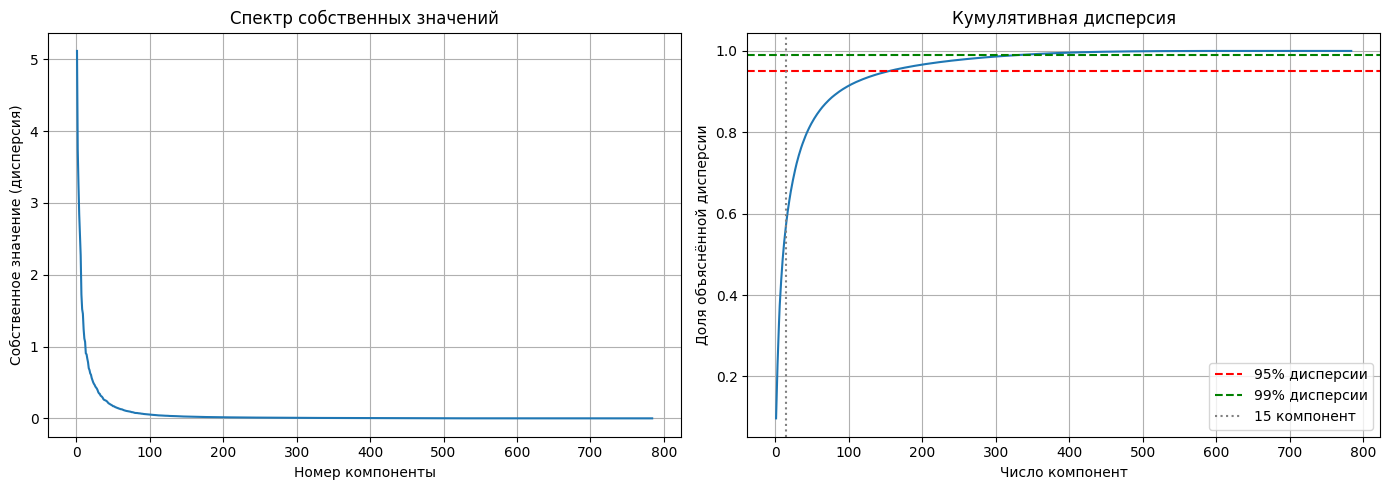

Первые 15 компонент объясняют 57.93% дисперсии
Для 90% дисперсии нужно 87 компонент
Для 95% дисперсии нужно 154 компонент
Для 99% дисперсии нужно 331 компонент
Собственных значений > 1e-10: 712 из 784 (пикселей, которые во всей выборке всегда 0: 67)
Сумма собственных значений = 52.726, суммарная дисперсия признаков = 52.725


In [6]:
# Обучаем PCA со всеми компонентами на всех 60 000 объектах
pca_full = my_PCA()
pca_full.fit(X)

cumulative = np.cumsum(pca_full.explained_variance_)
cumulative /= cumulative[-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: собственные значения
axes[0].plot(np.arange(1, len(pca_full.explained_variance_) + 1), pca_full.explained_variance_)
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Собственное значение (дисперсия)')
axes[0].set_title('Спектр собственных значений')
axes[0].grid(True)

# График 2: кумулятивная дисперсия
axes[1].plot(np.arange(1, len(cumulative) + 1), cumulative)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% дисперсии')
axes[1].axhline(y=0.99, color='g', linestyle='--', label='99% дисперсии')
axes[1].axvline(x=15, color='gray', linestyle=':', label='15 компонент')
axes[1].set_xlabel('Число компонент')
axes[1].set_ylabel('Доля объяснённой дисперсии')
axes[1].set_title('Кумулятивная дисперсия')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

n_95 = np.searchsorted(cumulative, 0.95) + 1
n_99 = np.searchsorted(cumulative, 0.99) + 1
print(f"Первые 15 компонент объясняют {cumulative[14]*100:.2f}% дисперсии")
print(f"Для 90% дисперсии нужно {np.searchsorted(cumulative, 0.90) + 1} компонент")
print(f"Для 95% дисперсии нужно {n_95} компонент")
print(f"Для 99% дисперсии нужно {n_99} компонент")
print(f"Собственных значений > 1e-10: {np.sum(pca_full.explained_variance_ > 1e-10)} из 784 "
      f"(пикселей, которые во всей выборке всегда 0: {np.sum(X.max(axis=0) == 0)})")
print(f"Сумма собственных значений = {pca_full.explained_variance_.sum():.3f}, "
      f"суммарная дисперсия признаков = {X.var(axis=0, ddof=1).sum():.3f}")

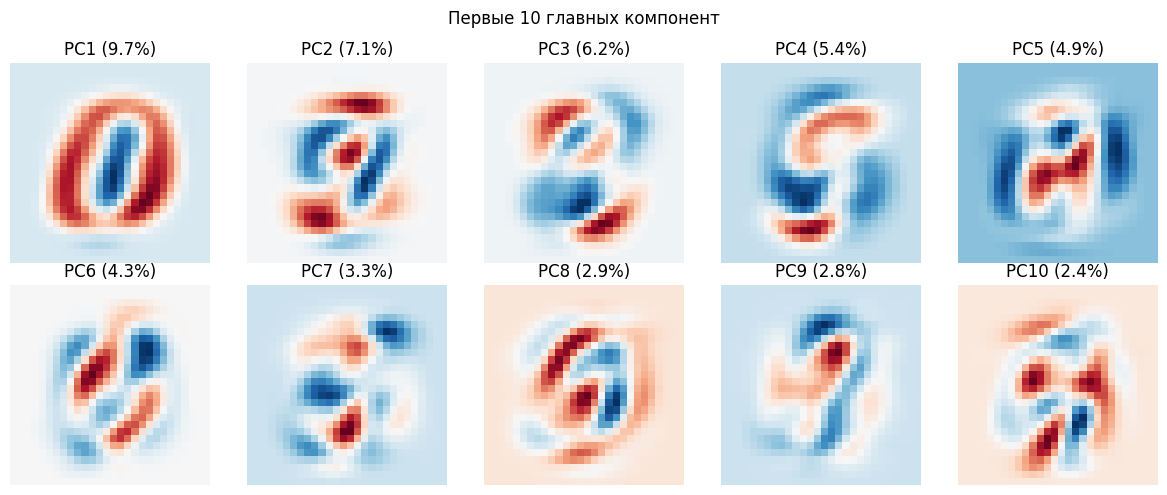

In [7]:
# Дополнительно: как выглядят первые главные компоненты ("собственные цифры")
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(pca_full.components_[i].reshape(28, 28), cmap='RdBu_r')
    ax.set_title(f"PC{i+1} ({pca_full.explained_variance_ratio_[i]*100:.1f}%)")
    ax.axis('off')
plt.suptitle('Первые 10 главных компонент')
plt.tight_layout()
plt.show()

**Ответы.**

1. Первые **15 главных компонент** покрывают **≈ 57,9%** дисперсии.
2. Для **95%** дисперсии нужно **154 компоненты** (для 90% — 87, для 99% — 331). Это в 5 раз меньше исходных 784 признаков.
3. **Связь собственных чисел и дисперсии.** Собственное число λᵢ матрицы ковариации — это дисперсия данных вдоль i-й главной оси: если спроецировать все объекты на вектор vᵢ, разброс проекций будет равен λᵢ. Первая компонента — направление, вдоль которого данные разбросаны сильнее всего, каждая следующая — направление максимального разброса среди ортогональных предыдущим. Сумма всех λᵢ равна суммарной дисперсии всех признаков (след матрицы ковариации): 52,726 ≈ 52,725, что видно в выводе выше. Поэтому доля λᵢ в сумме — это доля «информации» (разброса), которую сохраняет компонента.

Спектр убывает очень быстро: основную дисперсию несут первые десятки компонент. Около 70 последних собственных значений практически равны нулю: 67 пикселей (у краёв картинки) во всей выборке всегда чёрные и вообще не меняются. На картинках первых компонент видно, что они похожи на «размытые цифры»: например, PC1 противопоставляет широкий круг (0) и вертикальную черту (1).

### Задание 1.4: Визуализация данных в первых двух компонентах

Спроецируйте данные на первые две главные компоненты и постройте scatter plot, где разные цифры обозначены разными цветами.

```python
# TODO: Преобразуйте данные в первые 2 компоненты
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

# TODO: Постройте scatter plot
plt.figure(figsize=(10, 8))
# for digit in range(10):
#     mask = (y == digit)
#     plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.5, s=10)
# plt.legend()
# plt.xlabel('Первая главная компонента')
# plt.ylabel('Вторая главная компонента')
# plt.title('Данные MNIST в первых двух главных компонентах')
# plt.show()
```

**Вопрос:** Видны ли классы (цифры) раздельно в первых двух компонентах? Какие цифры визуально группируются вместе? Почему?

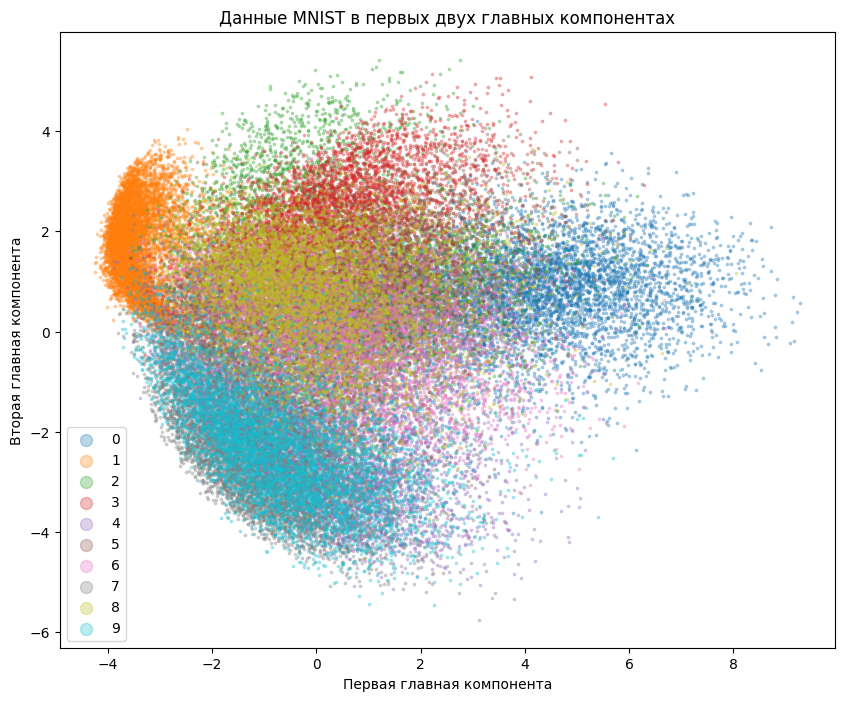

цифра 0: центр = (  3.93,   0.69)
цифра 1: центр = ( -3.30,   1.67)
цифра 2: центр = (  0.37,   1.21)
цифра 3: центр = (  0.29,   1.80)
цифра 4: центр = ( -0.23,  -2.26)
цифра 5: центр = (  0.42,   0.54)
цифра 6: центр = (  0.67,   0.00)
цифра 7: центр = ( -1.00,  -2.29)
цифра 8: центр = ( -0.01,   0.74)
цифра 9: центр = ( -0.60,  -2.23)


In [8]:
pca_2d = my_PCA(n_components=2)
Y_2d = pca_2d.fit_transform(X)

plt.figure(figsize=(10, 8))
for digit in range(10):
    mask = (y == digit)
    plt.scatter(Y_2d[mask, 0], Y_2d[mask, 1], label=str(digit), alpha=0.3, s=3)
plt.legend(markerscale=5)
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Данные MNIST в первых двух главных компонентах')
plt.show()

# Центры классов - чтобы было видно, какие цифры "накладываются"
for digit in range(10):
    cx, cy = Y_2d[y == digit].mean(axis=0)
    print(f"цифра {digit}: центр = ({cx:6.2f}, {cy:6.2f})")

**Ответ.** Классы видны лишь **частично**. Хорошо отделяются только:
- **1** (оранжевое облако слева): узкая вертикальная черта, мало закрашенных пикселей;
- **0** (синее облако справа): широкое кольцо, много пикселей по краям.

Фактически первая компонента — это «сколько пикселей закрашено и насколько широко»: от 1 до 0.

Сильно накладываются друг на друга:
- **4, 7, 9** (нижняя часть графика, центры ≈ (−1…0, −2,3)): у них похожее строение — вертикальная/наклонная черта справа и элемент сверху;
- **3, 5, 8** и **2** (центр графика, центры ≈ (0…0,4, 0,5…1,8)): у них похожие «закруглённые» формы и похожее количество чернил;
- **6** находится между ними.

Две компоненты объясняют лишь ~17% дисперсии, поэтому различия между похожими по общей форме цифрами (3/5/8, 4/9/7) остаются в следующих компонентах. Для разделения всех 10 классов двух измерений недостаточно.

## Часть 2. Метод k-ближайших соседей (kNN)

### Теория: Как работает kNN?

**Идея:** Объект относится к тому классу, к которому принадлежит **большинство** из его $k$ ближайших соседей в обучающей выборке.

**Алгоритм предсказания для объекта $x$:**
1. Найти расстояния от $x$ до всех объектов обучающей выборки
2. Выбрать $k$ объектов с наименьшими расстояниями
3. Найти самый частый класс среди этих $k$ объектов
4. Вернуть этот класс как предсказание

**Метрика расстояния:** Обычно используется **евклидово расстояние**:
$$ d(x, x') = \sqrt{\sum_{i=1}^{d} (x_i - x'_i)^2} $$

### Задание 2.1: Реализация my_kNN

```python
class my_kNN:
    def __init__(self, n_neighbors=5):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        """
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None
    
    def fit(self, X, y):
        """
        Запоминает обучающую выборку.
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        y : np.array, shape (n_samples,)
        """
        # TODO: Сохраните X и y
        pass
    
    def predict(self, X):
        """
        Предсказывает классы для объектов X.
        
        Для каждого объекта x из X:
        1. Вычислите расстояние до всех объектов X_train
        2. Найдите k ближайших
        3. Верните самый частый класс
        
        Parameters
        ----------
        X : np.array, shape (n_samples, n_features)
        
        Returns
        -------
        y_pred : np.array, shape (n_samples,)
        """
        # TODO: Реализуйте предсказание
        # Подсказка: используйте np.argsort для поиска k ближайших
        # Для подсчёта самого частого класса используйте np.bincount или scipy.stats.mode
        pass
```

**Подсказка по эффективности:** Если вычислять расстояния в цикле по объектам, это может быть медленно. Используйте матричные операции:
- Для вычисления матрицы расстояний можно применить формулу: $\|x - x'\|^2 = \|x\|^2 + \|x'\|^2 - 2 \langle x, x' \rangle$

In [9]:
class my_kNN:
    def __init__(self, n_neighbors=5, batch_size=1000):
        """
        Parameters
        ----------
        n_neighbors : int
            Число соседей
        batch_size : int
            Сколько тестовых объектов обрабатывать за раз (ограничивает память под матрицу расстояний)
        """
        self.n_neighbors = n_neighbors
        self.batch_size = batch_size
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        """Запоминает обучающую выборку."""
        self.X_train = np.asarray(X, dtype=np.float32)
        self.y_train = np.asarray(y)
        self.classes_, self._y_idx = np.unique(self.y_train, return_inverse=True)
        self._train_sq = np.sum(self.X_train**2, axis=1)   # ||x'||^2 считаем один раз
        return self

    def kneighbors(self, X, n_neighbors=None):
        """Индексы n_neighbors ближайших объектов обучающей выборки (по возрастанию расстояния)."""
        k = n_neighbors or self.n_neighbors
        X = np.asarray(X, dtype=np.float32)
        result = np.empty((X.shape[0], k), dtype=np.int64)
        for start in range(0, X.shape[0], self.batch_size):
            batch = X[start:start + self.batch_size]
            # ||x - x'||^2 = ||x||^2 + ||x'||^2 - 2<x, x'>  (квадрат корня не меняет порядок,
            # поэтому sqrt не нужен)
            d2 = np.sum(batch**2, axis=1)[:, None] + self._train_sq[None, :] - 2 * batch @ self.X_train.T
            # argpartition находит k наименьших за O(n), затем сортируем только эти k
            nn = np.argpartition(d2, k - 1, axis=1)[:, :k]
            order = np.argsort(np.take_along_axis(d2, nn, axis=1), axis=1)
            result[start:start + len(batch)] = np.take_along_axis(nn, order, axis=1)
        return result

    def _vote(self, neighbors):
        """Самый частый класс среди соседей (при равенстве - меньшая метка, как в sklearn)."""
        labels = self._y_idx[neighbors]                         # (m, k)
        counts = np.zeros((labels.shape[0], len(self.classes_)), dtype=np.int32)
        np.add.at(counts, (np.arange(labels.shape[0])[:, None], labels), 1)
        return self.classes_[np.argmax(counts, axis=1)]

    def predict(self, X):
        """Предсказывает классы для объектов X, shape (n_samples, n_features)."""
        return self._vote(self.kneighbors(X))

### Задание 2.2: Проверка реализации

Убедитесь, что ваш kNN работает правильно:

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Обучите свой kNN
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f}")
```

**Вопрос:** Если точность около **10%**, значит алгоритм работает как случайный (10 классов). Если точность **>90%**, всё хорошо. Какая у вас точность?

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# kNN на всех 60 000 объектах считается долго (особенно в экспериментах с перебором параметров),
# поэтому, как разрешено в подсказках, берём случайную подвыборку.
# Поставьте N_SUBSET = None, чтобы использовать все данные.
N_SUBSET = 20000
rng = np.random.default_rng(42)
if N_SUBSET is not None:
    sub = rng.choice(len(X), size=N_SUBSET, replace=False)
    X_sub, y_sub = X[sub], y[sub]
else:
    X_sub, y_sub = X, y

# Разделим данные
X_train, X_test, y_train, y_test = train_test_split(
    X_sub, y_sub, test_size=0.3, random_state=42
)
print(f"Обучение: {X_train.shape}, тест: {X_test.shape}")

# Обучите свой kNN
start = time.time()
my_knn = my_kNN(n_neighbors=5)
my_knn.fit(X_train, y_train)
y_pred_my = my_knn.predict(X_test)
time_my = time.time() - start

accuracy_my = accuracy_score(y_test, y_pred_my)
print(f"Точность my_kNN: {accuracy_my:.4f} (время {time_my:.2f} с)")

Обучение: (14000, 784), тест: (6000, 784)


Точность my_kNN: 0.9533 (время 1.99 с)


**Ответ.** Точность `my_kNN` (k = 5) — **≈ 95,3%**, что намного выше случайных 10%, т.е. алгоритм работает правильно.

Замечание: эксперименты частей 2–3 проводятся на случайной подвыборке из 20 000 изображений (14 000 обучение / 6 000 тест), как разрешено в подсказках, чтобы перебор параметров занимал секунды, а не десятки минут. На полной выборке точность kNN обычно ещё немного выше (в литературе ~97% для k = 3–5), так как соседей больше. Чтобы использовать все данные, достаточно поставить `N_SUBSET = None`.

Для скорости расстояния считаются матрично по формуле ‖x−x'‖² = ‖x‖² + ‖x'‖² − 2⟨x, x'⟩ пачками по 1000 объектов (чтобы не выделять сразу матрицу 6000×14000), а k ближайших ищутся через `np.argpartition` за линейное время вместо полной сортировки.

### Задание 2.3: Сравнение с sklearn

Сравните ваш kNN с `sklearn.neighbors.KNeighborsClassifier`:

```python
from sklearn.neighbors import KNeighborsClassifier

# Обучите sklearn kNN
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f}")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
```

**Вопрос:** Совпадают ли результаты? Если разница большая, проверьте реализацию.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

start = time.time()
sk_knn = KNeighborsClassifier(n_neighbors=5)
sk_knn.fit(X_train, y_train)
y_pred_sk = sk_knn.predict(X_test)
time_sk = time.time() - start

accuracy_sk = accuracy_score(y_test, y_pred_sk)
print(f"Точность sklearn kNN: {accuracy_sk:.4f} (время {time_sk:.2f} с)")
print(f"Разница: {abs(accuracy_my - accuracy_sk):.4f}")
print(f"Предсказания совпадают для {np.mean(y_pred_my == y_pred_sk)*100:.2f}% объектов")

Точность sklearn kNN: 0.9533 (время 2.44 с)
Разница: 0.0000
Предсказания совпадают для 100.00% объектов


**Ответ.** Да, результаты **полностью совпадают**: точность одинакова (разница 0,0000), и предсказания совпадают для 100% объектов. Время работы тоже сравнимо с sklearn (обе реализации — полный перебор с матричным вычислением расстояний).

### Задание 2.4: Эксперимент с числом соседей

Исследуйте, как зависит точность от числа соседей $k$. Попробуйте $k \in \{1, 3, 5, 7, 10, 15, 20, 30\}$.

```python
# TODO: Постройте график зависимости accuracy от k
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    # TODO: Обучите kNN, посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(8, 5))
# plt.plot(k_values, accuracies, 'o-')
# plt.xlabel('Число соседей k')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа соседей')
# plt.grid(True)
# plt.show()
```

**Вопрос:** При каком $k$ точность максимальна? Почему при малых $k$ точность ниже? А при слишком больших?

k =  1: accuracy = 0.9583


k =  3: accuracy = 0.9518


k =  5: accuracy = 0.9533


k =  7: accuracy = 0.9540


k = 10: accuracy = 0.9452


k = 15: accuracy = 0.9413


k = 20: accuracy = 0.9385


k = 30: accuracy = 0.9295

Лучшее k = 1, accuracy = 0.9583


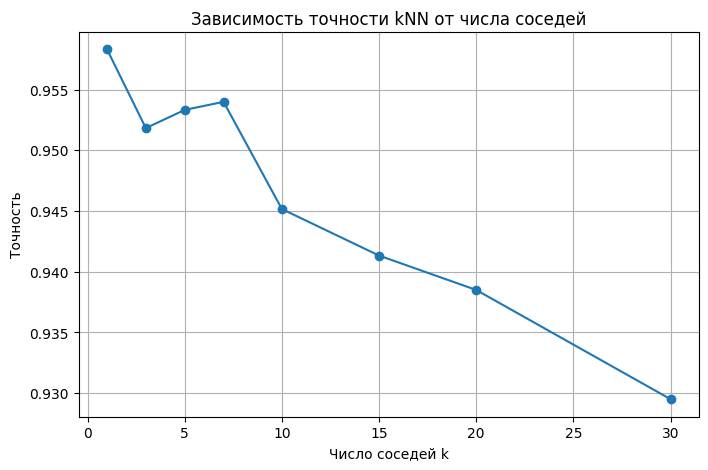

In [12]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30]
accuracies = []

for k in k_values:
    knn = my_kNN(n_neighbors=k).fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    accuracies.append(acc)
    print(f"k = {k:2d}: accuracy = {acc:.4f}")

best_k = k_values[int(np.argmax(accuracies))]
print(f"\nЛучшее k = {best_k}, accuracy = {max(accuracies):.4f}")

plt.figure(figsize=(8, 5))
plt.plot(k_values, accuracies, 'o-')
plt.xlabel('Число соседей k')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа соседей')
plt.grid(True)
plt.show()

**Ответы.**
- Максимальная точность на нашей подвыборке достигается при **k = 1** (≈ 95,8%). Близкие значения дают k = 5–7 (≈ 95,3–95,4%). Дальше с ростом k точность монотонно падает до ≈ 93% при k = 30.
- **При малых k** модель чувствительна к шуму: решение принимается по одному-двум соседям, и если ближайший объект — неаккуратно написанная цифра или выброс, ответ будет ошибочным (переобучение, высокая дисперсия). Здесь видно, что k = 3 даже чуть хуже k = 1: если трое соседей принадлежат трём разным классам, ничья решается в пользу меньшей метки, а не ближайшего соседа.
- **При больших k** в «окрестность» попадают объекты, далёкие от x, в том числе из других, похожих классов (4/9, 3/5/8). Голосование «размывается», граница между классами сглаживается, модель становится слишком простой (недообучение, высокое смещение).
- На MNIST k = 1 работает так хорошо, потому что данных много и одинаковые цифры образуют плотные «облака»: ближайший сосед почти всегда того же класса. Оптимальное k зависит от размера выборки и уровня шума и выбирается по валидации.

## Часть 3. PCA + kNN: Понижение размерности для классификации

### Теория: Зачем комбинировать PCA и kNN?

**Проблемы kNN на полных данных:**
- **Вычислительная сложность:** расстояние считается по 784 признакам
- **"Проклятие размерности":** в высоких размерностях расстояния между точками становятся похожими
- **Шум:** неинформативные признаки мешают

**Решение:** Сначала уменьшить размерность с помощью PCA, потом обучить kNN.

**Вопрос для размышления:** Как вы думаете, улучшится ли качество? А скорость работы?

### Задание 3.1: Применение PCA перед kNN

Обучите последовательно: PCA (с разным числом компонент) → kNN.

```python
# TODO: Переберите число компонент от 1 до 100
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []

for n_comp in n_components_list:
    # TODO: 
    # 1. Примените PCA к X_train и X_test
    # 2. Обучите kNN на преобразованных данных
    # 3. Посчитайте accuracy
    pass

# TODO: Постройте график
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, accuracies_pca, 'o-')
# plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
# plt.xlabel('Число главных компонент')
# plt.ylabel('Точность')
# plt.title('Зависимость точности kNN от числа компонент PCA')
# plt.legend()
# plt.grid(True)
# plt.show()
```

**Вопросы:**
1. При каком числе компонент точность максимальна?
2. Удалось ли превзойти точность kNN на всех 784 признаках?
3. Что происходит при слишком малом числе компонент? Почему?

n_components =   1: accuracy = 0.2698, время = 4.15 с (kNN 1.39 с)


n_components =   2: accuracy = 0.4238, время = 4.05 с (kNN 1.37 с)


n_components =   5: accuracy = 0.7355, время = 4.00 с (kNN 1.38 с)


n_components =  10: accuracy = 0.9207, время = 4.19 с (kNN 1.43 с)


n_components =  15: accuracy = 0.9473, время = 4.12 с (kNN 1.43 с)


...

n_components = 100: accuracy = 0.9567, время = 4.35 с (kNN 1.45 с)


n_components = 200: accuracy = 0.9547, время = 4.38 с (kNN 1.52 с)


n_components = 300: accuracy = 0.9533, время = 4.47 с (kNN 1.54 с)


n_components = 500: accuracy = 0.9532, время = 4.56 с (kNN 1.78 с)


n_components = 784: accuracy = 0.9533, время = 4.88 с (kNN 2.06 с)

Лучшее число компонент: 30, accuracy = 0.9625 (kNN на всех признаках: 0.9533)


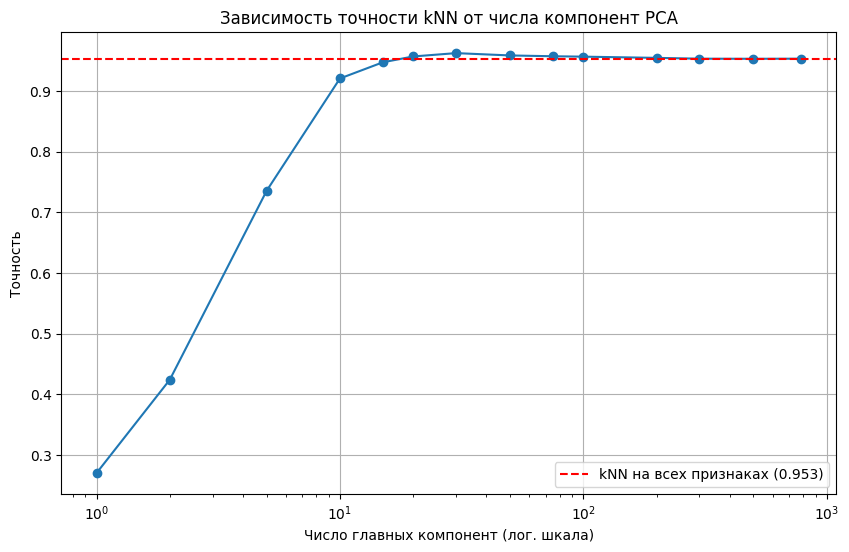

In [13]:
n_components_list = [1, 2, 5, 10, 15, 20, 30, 50, 75, 100, 200, 300, 500, 784]
accuracies_pca = []
times = []        # полное время: PCA + kNN (обучение и предсказание)
times_knn = []    # только kNN

for n_comp in n_components_list:
    start = time.time()
    # 1. PCA обучаем ТОЛЬКО на обучающей выборке и применяем к обеим (без утечки теста)
    pca = my_PCA(n_components=n_comp).fit(X_train)
    Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)
    t_knn = time.time()
    # 2. Обучаем kNN на преобразованных данных
    knn = my_kNN(n_neighbors=5).fit(Z_train, y_train)
    y_pred = knn.predict(Z_test)
    end = time.time()
    # 3. Accuracy
    acc = accuracy_score(y_test, y_pred)
    accuracies_pca.append(acc)
    times.append(end - start)
    times_knn.append(end - t_knn)
    print(f"n_components = {n_comp:3d}: accuracy = {acc:.4f}, время = {end - start:.2f} с (kNN {end - t_knn:.2f} с)")

best_n = n_components_list[int(np.argmax(accuracies_pca))]
print(f"\nЛучшее число компонент: {best_n}, accuracy = {max(accuracies_pca):.4f} "
      f"(kNN на всех признаках: {accuracy_my:.4f})")

plt.figure(figsize=(10, 6))
plt.plot(n_components_list, accuracies_pca, 'o-')
plt.axhline(y=accuracy_my, color='r', linestyle='--', label=f'kNN на всех признаках ({accuracy_my:.3f})')
plt.xscale('log')
plt.xlabel('Число главных компонент (лог. шкала)')
plt.ylabel('Точность')
plt.title('Зависимость точности kNN от числа компонент PCA')
plt.legend()
plt.grid(True)
plt.show()

**Ответы.**
1. Максимальная точность достигается при **≈ 30 компонентах** (≈ 96,25% при k = 5). Значения от 20 до 100 компонент дают почти такое же качество (95,7–96,2%).
2. **Да**, удалось превзойти kNN на всех 784 признаках (95,33%) примерно на 1 процентный пункт. При 784 компонентах точность ровно такая же, как без PCA. Так и должно быть: PCA со всеми компонентами — это только поворот системы координат и сдвиг, а евклидовы расстояния от них не меняются.
3. **При слишком малом числе компонент** (1–5) точность резко падает (27% при 1 компоненте, 42% при 2, 74% при 5): в проекции теряется большая часть информации, и разные цифры, как мы видели на scatter-plot, накладываются друг на друга. Расстояния в таком пространстве уже не отражают реальное сходство изображений.

Почему PCA улучшает качество: последние компоненты с малой дисперсией описывают в основном шум и индивидуальные особенности почерка (толщину линии, мелкие сдвиги), а не форму цифры. Их отбрасывание убирает шум из расстояний, и соседи определяются по существенным признакам.

### Задание 3.2: Исследование времени работы

Замерьте время работы kNN с разным числом компонент.

```python
import time

# TODO: Замерьте время для разных n_components
times = []
for n_comp in n_components_list:
    start = time.time()
    # ... обучение и предсказание ...
    elapsed = time.time() - start
    times.append(elapsed)

# TODO: Постройте график времени
plt.figure(figsize=(10, 6))
# plt.plot(n_components_list, times, 'o-')
# plt.xlabel('Число компонент')
# plt.ylabel('Время (сек)')
# plt.title('Время работы kNN в зависимости от числа компонент')
# plt.grid(True)
# plt.show()
```

**Вопрос:** Как изменяется время работы при уменьшении размерности? Объясните.

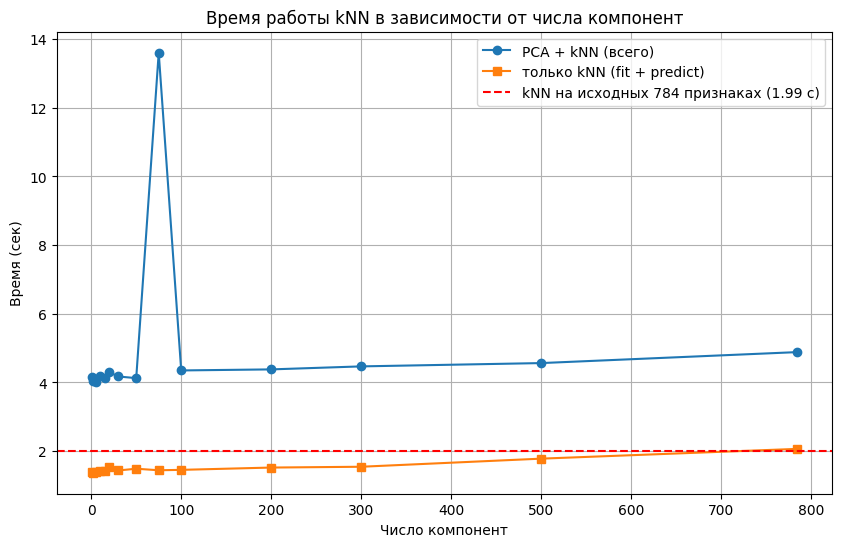

n_components =   1: всего 4.15 с, kNN 1.39 с
n_components =   2: всего 4.05 с, kNN 1.37 с
n_components =   5: всего 4.00 с, kNN 1.38 с
n_components =  10: всего 4.19 с, kNN 1.43 с
n_components =  15: всего 4.12 с, kNN 1.43 с
n_components =  20: всего 4.30 с, kNN 1.54 с
n_components =  30: всего 4.17 с, kNN 1.43 с
n_components =  50: всего 4.12 с, kNN 1.48 с
n_components =  75: всего 13.60 с, kNN 1.44 с
n_components = 100: всего 4.35 с, kNN 1.45 с
n_components = 200: всего 4.38 с, kNN 1.52 с
n_components = 300: всего 4.47 с, kNN 1.54 с
n_components = 500: всего 4.56 с, kNN 1.78 с
n_components = 784: всего 4.88 с, kNN 2.06 с


In [14]:
# Время уже замерено в цикле задания 3.1 (одновременно с подсчётом точности),
# чтобы не повторять одни и те же вычисления дважды.
plt.figure(figsize=(10, 6))
plt.plot(n_components_list, times, 'o-', label='PCA + kNN (всего)')
plt.plot(n_components_list, times_knn, 's-', label='только kNN (fit + predict)')
plt.axhline(y=time_my, color='r', linestyle='--', label=f'kNN на исходных 784 признаках ({time_my:.2f} с)')
plt.xlabel('Число компонент')
plt.ylabel('Время (сек)')
plt.title('Время работы kNN в зависимости от числа компонент')
plt.legend()
plt.grid(True)
plt.show()

for n_comp, t, tk in zip(n_components_list, times, times_knn):
    print(f"n_components = {n_comp:3d}: всего {t:.2f} с, kNN {tk:.2f} с")

**Ответ.** На этом объёме данных время работы **почти не зависит** от числа компонент: kNN занимает ~1,3–1,5 с при 1–300 компонентах и ~2 с при 784. Полное время (PCA + kNN) — около 4–5 с, большую часть занимает обучение PCA (полный SVD обучающей матрицы 14 000×784), а оно не зависит от числа сохраняемых компонент. Точные значения времени немного меняются от запуска к запуску.

Объяснение. Для полного перебора kNN нужно для каждой пары (тест, обучение) вычислить расстояние — O(m·n·d) операций — и затем найти k минимальных среди n расстояний — O(m·n). Скалярные произведения считаются одним матричным умножением, а оно на современных процессорах (BLAS, многопоточность) настолько быстрое, что при d ≤ 784 узким местом становится работа с самой матрицей расстояний 6000×14000 (поиск k ближайших, выделение памяти), которая от d не зависит. Поэтому выигрыш от снижения размерности здесь скромный (~30% при переходе с 784 до ≲ 300 признаков).

Выигрыш станет заметнее при более медленной реализации (цикл по объектам), на больших выборках, а также при использовании деревьев (KD-tree, Ball-tree), которые хорошо работают лишь в низкой размерности (~до 20–50 признаков). Кроме того, после PCA данные занимают в 784/n_comp раз меньше памяти.

### Задание 3.3: Финальный эксперимент — сетка параметров

Проведите **совместный** перебор параметров:
- Число компонент PCA: $[5, 10, 15, 20, 30, 50, 100]$
- Число соседей $k$: $[1, 3, 5, 7, 10]$

Для каждой комбинации посчитайте точность. Постройте **heatmap** (тепловую карту) с точностью.

```python
# TODO: Переберите все комбинации
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Примените PCA
    # ...
    for j, k in enumerate(k_grid):
        # Обучите kNN
        # ...
        pass

# TODO: Постройте heatmap
import seaborn as sns
plt.figure(figsize=(10, 6))
# sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
#             xticklabels=k_grid, yticklabels=n_components_grid,
#             cmap='viridis')
# plt.xlabel('Число соседей k')
# plt.ylabel('Число компонент PCA')
# plt.title('Точность классификации MNIST')
# plt.show()
```

**Вопросы:**
1. Какая комбинация параметров даёт **наилучшую** точность?
2. Какая — **наихудшую**?
3. Есть ли комбинации, где точность **выше**, чем у kNN на полных данных? Что это говорит о PCA?

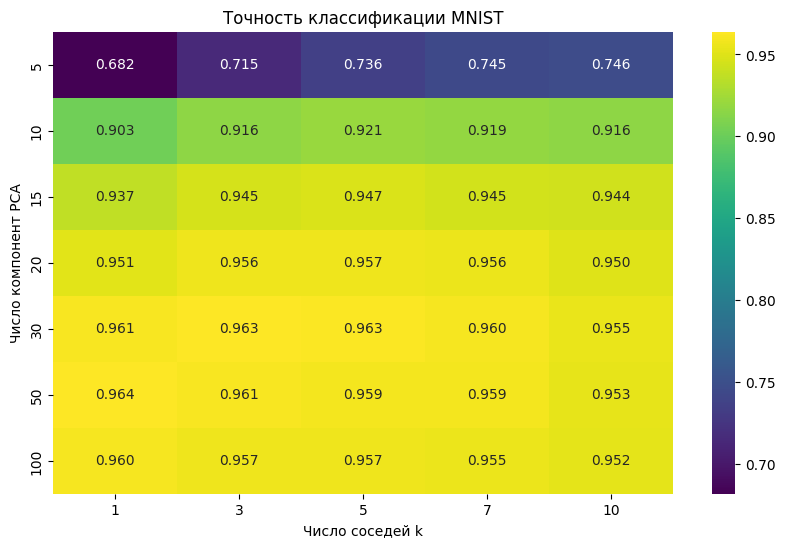

Лучшая комбинация: n_components = 50, k = 1, accuracy = 0.9638
Худшая комбинация: n_components = 5, k = 1, accuracy = 0.6820

Комбинаций лучше, чем kNN (k=5) на всех признаках (0.9533): 16
  n_components =  50, k =  1: 0.9638
  n_components =  30, k =  3: 0.9632
  n_components =  30, k =  5: 0.9625
  n_components =  30, k =  1: 0.9613
  n_components =  50, k =  3: 0.9607
  n_components =  30, k =  7: 0.9595
  n_components = 100, k =  1: 0.9595
  n_components =  50, k =  7: 0.9588
  n_components =  50, k =  5: 0.9587
  n_components = 100, k =  3: 0.9572
  n_components =  20, k =  5: 0.9570
  n_components = 100, k =  5: 0.9567
  n_components =  20, k =  3: 0.9562
  n_components =  20, k =  7: 0.9560
  n_components = 100, k =  7: 0.9552
  n_components =  30, k = 10: 0.9550


In [15]:
n_components_grid = [5, 10, 15, 20, 30, 50, 100]
k_grid = [1, 3, 5, 7, 10]

accuracy_matrix = np.zeros((len(n_components_grid), len(k_grid)))

for i, n_comp in enumerate(n_components_grid):
    # Применяем PCA (один раз на каждое число компонент)
    pca = my_PCA(n_components=n_comp).fit(X_train)
    Z_train, Z_test = pca.transform(X_train), pca.transform(X_test)
    # Соседей ищем один раз для максимального k: первые k из отсортированного
    # списка - это и есть k ближайших для любого меньшего k
    knn = my_kNN(n_neighbors=max(k_grid)).fit(Z_train, y_train)
    neighbors = knn.kneighbors(Z_test)
    for j, k in enumerate(k_grid):
        y_pred = knn._vote(neighbors[:, :k])
        accuracy_matrix[i, j] = accuracy_score(y_test, y_pred)

plt.figure(figsize=(10, 6))
sns.heatmap(accuracy_matrix, annot=True, fmt='.3f',
            xticklabels=k_grid, yticklabels=n_components_grid,
            cmap='viridis')
plt.xlabel('Число соседей k')
plt.ylabel('Число компонент PCA')
plt.title('Точность классификации MNIST')
plt.show()

bi, bj = np.unravel_index(np.argmax(accuracy_matrix), accuracy_matrix.shape)
wi, wj = np.unravel_index(np.argmin(accuracy_matrix), accuracy_matrix.shape)
print(f"Лучшая комбинация: n_components = {n_components_grid[bi]}, k = {k_grid[bj]}, "
      f"accuracy = {accuracy_matrix[bi, bj]:.4f}")
print(f"Худшая комбинация: n_components = {n_components_grid[wi]}, k = {k_grid[wj]}, "
      f"accuracy = {accuracy_matrix[wi, wj]:.4f}")
better = [(n_components_grid[i], k_grid[j], accuracy_matrix[i, j])
          for i in range(len(n_components_grid)) for j in range(len(k_grid))
          if accuracy_matrix[i, j] > accuracy_my]
print(f"\nКомбинаций лучше, чем kNN (k=5) на всех признаках ({accuracy_my:.4f}): {len(better)}")
for n_comp, k, acc in sorted(better, key=lambda t: -t[2]):
    print(f"  n_components = {n_comp:3d}, k = {k:2d}: {acc:.4f}")

**Ответы.**
1. **Лучшая** комбинация: **50 компонент, k = 1** (≈ 96,4%). Почти так же хороши 30 компонент с k = 3 или 5 (≈ 96,3%).
2. **Худшая** комбинация: **5 компонент, k = 1** (≈ 68,2%). При малой размерности классы сильно перекрываются, и один ближайший сосед часто оказывается «чужим». Здесь, в отличие от больших размерностей, увеличение k помогает (до 74,6% при k = 10): голосование нескольких соседей сглаживает перекрытие.
3. **Да**, таких комбинаций много: 16 из 35 превосходят kNN на полных данных (95,33%). Все они находятся в области 20–100 компонент. Это говорит о том, что **PCA работает не только как сжатие, но и как фильтр шума**: информация, существенная для распознавания цифр, сосредоточена в нескольких десятках главных направлений, а остальные сотни признаков в основном добавляют шум в расстояния. Оптимальная область на тепловой карте — **30–50 компонент и k = 1–5**.

## Часть 4. Выводы (в конце ноутбука, обязательно)

Напишите текстовый вывод (5-10 предложений) по всей работе. Ответьте на вопросы:

1. **Что такое PCA?** Как он работает? Зачем нужен?
2. **Что такое kNN?** Как работает? Какие у него есть плюсы и минусы?
3. **Как PCA влияет на качество kNN?** Что лучше — использовать все признаки или уменьшить размерность?
4. **Какова оптимальная размерность для MNIST?** Почему?
5. **Что было самым сложным** при выполнении работы?
6. **Что было самым интересным?**

## Выводы

1. **PCA** — линейный метод понижения размерности. Он центрирует данные и находит ортогональные направления (собственные векторы матрицы ковариации) с максимальной дисперсией. Собственные значения равны дисперсии вдоль этих направлений. На практике PCA удобно и устойчиво вычислять через SVD центрированной матрицы данных, что и сделано в `my_PCA` (результат совпадает со sklearn до ~10⁻⁶). PCA нужен для сжатия данных, удаления шума и коррелированных признаков, визуализации и ускорения других алгоритмов.
2. **kNN** — метрический классификатор: объект относится к классу, который чаще всего встречается среди его k ближайших соседей. Плюсы: простота, отсутствие обучения, нелинейные границы классов, хорошее качество при большом объёме данных (≈ 95–96% на MNIST). Минусы: медленное предсказание и большие затраты памяти (нужно хранить всю выборку и считать расстояния до всех объектов), чувствительность к масштабу и неинформативным признакам, «проклятие размерности», необходимость подбирать k. Наша векторизованная реализация `my_kNN` дала те же предсказания, что и sklearn.
3. **Влияние PCA на kNN.** При 20–100 компонентах точность kNN **выше**, чем на всех 784 признаках (до 96,4% против 95,3%), потому что отброшенные компоненты с малой дисперсией несут в основном шум. Слишком сильное сжатие (≤ 10 компонент) резко ухудшает качество. Уменьшать размерность разумно, но в меру.
4. **Оптимальная размерность для MNIST** — около **30–50 компонент**. Они объясняют лишь ~73–82% дисперсии, но этого достаточно для лучшей точности, поскольку форма цифры описывается небольшим числом главных направлений. Для сохранения 95% дисперсии (точного восстановления картинок) нужно 154 компоненты, но для классификации это избыточно.
5. **Самым сложным** было эффективно реализовать kNN: наивный вариант с циклами работал бы очень долго. Пришлось использовать матричную формулу расстояний, обработку пачками и `argpartition`. Также потребовалось разобраться, почему собственные значения слегка отличаются от sklearn: по умолчанию там используется приближённый рандомизированный SVD.
6. **Самым интересным** оказалось, что, *выбрасывая* информацию (с 784 до 30–50 признаков), можно *улучшить* качество классификации. Ещё интересно было увидеть сами главные компоненты в виде «размытых цифр» и то, как уже две компоненты отделяют 0 от 1.

## Подсказки и советы

### Совет 1: Используйте SVD вместо eig
В `my_PCA.fit()` используйте `np.linalg.svd`, а не `np.linalg.eig`. SVD работает быстрее и численно устойчивее.

### Совет 2: Проверяйте размерности
После каждого преобразования выводите `shape` массивов. Это поможет избежать ошибок.

### Совет 3: kNN может работать медленно
Если предсказание занимает больше минуты, попробуйте:
- Уменьшить выборку (взять первые 5000 объектов)
- Использовать матричные вычисления расстояний

### Совет 4: Не бойтесь экспериментировать
Если что-то не работает как ожидается — меняйте параметры, рисуйте графики, смотрите на данные.

### Совет 5: Интерпретируйте результаты
Не просто стройте графики, а **объясняйте**, что вы видите. Например: "Точность падает при k > 15, потому что..."

**Удачи!**